# Ranking feature analysis — what is worth using (leak-free)?

**Question (a)**: the day before a season starts, predict the final regular-season ranking of every
team *inside its conference* (two rankings of ~15 teams per season).

This notebook decides **what goes into the prediction models** in `ranking_predictions.ipynb`.
Every decision is made on seasons **before 2005** (`TEST_START_YEAR`); 2005–2009 is kept for the
final, clean evaluation.

Two design choices are important:

* **Target = points percentage.** We use ``Pts / (2 * GP)`` instead of raw points or wins, because
  it is comparable across 80-game, 82-game and shortened (48-game) seasons.
* **No leak.** Coach columns and current-season roster composition are excluded. Every
  team-performance feature is lagged: season *Y-1* predicts season *Y*.

> **Protocol in one line**: for each season *Y*, train on every season `< Y` and predict *Y*.
> Never use information from *Y* or later.

## 1. Data and feature blocks

The base dataset is `data_prepared/teams.csv` (prepared by `data_preparation.ipynb`). Raw points and
games are read from `data/Teams.csv` to compute points percentage. The external features are built
from the raw tables:

| File | What it contributes |
|---|---|
| `data/Teams.csv` | raw points, games, goals, special teams, penalties |
| `data/Scoring.csv` | team shots |
| `data/Goalies.csv` | team save %, starter workload and quality |
| `data/SeriesPost.csv`, `data/TeamsPost.csv` | playoff history |
| `data/AwardsPlayers.csv` | awards won by the previous roster |
| `data/TeamSplits.csv` | home/road and second-half performance |

**Excluded on purpose** (leak or other task):

* `coach_changed`, `previous_coach_tenure`, `previous_coach_interim`, `coaches_last_3y` — coach
  information, target of the separate coach-change task;
* current-season roster composition (top-3/top-6 forwards, top-4 defencemen, age, size,
  continuity) — the roster is only known after the season, including in-season arrivals;
* every current-season team statistic is used **only lagged**, never as a same-season feature.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

# Make the helper modules importable whether the notebook is run from the project root
# or from the ranking/ directory.
for candidate in [Path.cwd(), Path.cwd() / "ranking"]:
    if (candidate / "ranking_utils.py").exists():
        sys.path.insert(0, str(candidate))
        break

import ranking_utils as ru
import ranking_features as rf

teams = ru.load_teams()
df = ru.build_dataset(teams)
groups = ru.feature_groups(df)

ext, EXT_GROUPS = rf.build_external_features(ru.DATA_DIR)
df = df.merge(ext.drop(columns=["franchID"]), on=["year", "tmID"], how="left")
EXT_COLS = [c for cols in EXT_GROUPS.values() for c in cols]
df[EXT_COLS] = df[EXT_COLS].fillna(0.0)

ALL_GROUPS = {**groups, **EXT_GROUPS}
ALL_FEATURES = ru.flatten(ALL_GROUPS)

BASE_GROUPS = ["prev_points", "history_points"]
BASE_FEATURES = ru.flatten(groups, BASE_GROUPS)

dev = df[df["year"] < ru.TEST_START_YEAR].copy()
SELECTION_YEARS = [y for y in sorted(dev["year"].unique()) if y >= 1995]

print(f"{len(df)} team-seasons, {df['year'].min()}-{df['year'].max()}")
print(f"Development part (<{ru.TEST_START_YEAR}): {len(dev)} rows | selection years: {SELECTION_YEARS[0]}-{SELECTION_YEARS[-1]}")
print(f"\nBase feature groups ({len(BASE_FEATURES)} features):")
for name in BASE_GROUPS:
    print(f"  {name:15s} {groups[name]}")
print(f"\nExternal feature blocks ({len(EXT_COLS)} features):")
for name, cols in EXT_GROUPS.items():
    print(f"  {name:15s} {len(cols):2d} features")

732 team-seasons, 1980-2009
Development part (<2005): 582 rows | selection years: 1995-2003

Base feature groups (7 features):
  prev_points     ['pts_pct_z_lag1']
  history_points  ['pts_pct_z_lag2', 'pts_pct_z_lag3', 'pts_pct_z_lag4', 'pts_pct_z_lag5', 'pts_pct_z_mean3', 'pts_pct_z_mean5']

External feature blocks (25 features):
  shots_luck       7 features
  special_teams    3 features
  goalie           5 features
  playoff_history  4 features
  awards           3 features
  splits           3 features


## 2. Why points percentage?

Points percentage is ``Pts / (2 * GP)``, so it always lies in [0, 1] and does not depend on the
number of games played. Raw points and wins are distorted by shortened seasons (the lockout-shortened
1994 season in this dataset has 48 games) and by era changes in the schedule. The left panel below shows the number of
games per season; the middle panel shows that mean raw points move with the schedule; the right panel
shows that points percentage stays on a stable scale.

Lockout-shortened seasons (< 70 games):
      games  points_mean  pct_mean
year                              
1994     48         48.0       0.5


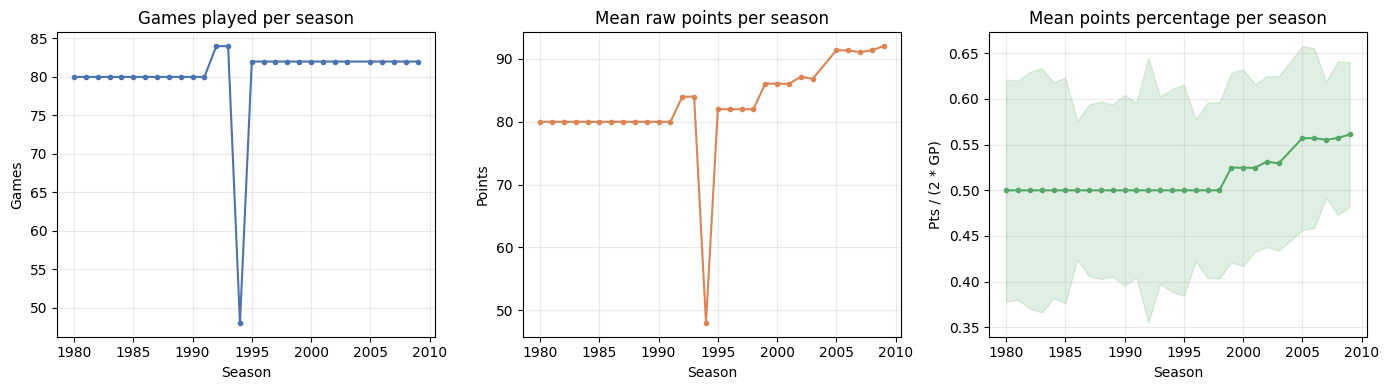

Target = z-score of points percentage. It has mean -0.00 and standard deviation 0.98 by construction.


In [2]:
season_info = teams.groupby("year").agg(
    games=("games_raw", "first"),
    points_mean=("pts_raw", "mean"),
    pct_mean=("pts_pct", "mean"),
    pct_std=("pts_pct", "std"),
)
short = season_info[season_info["games"] < 70]
print("Lockout-shortened seasons (< 70 games):")
print(short[["games", "points_mean", "pct_mean"]].round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(season_info.index, season_info["games"], marker="o", ms=3, color="#4C72B0")
axes[0].set_title("Games played per season")
axes[0].set_xlabel("Season"); axes[0].set_ylabel("Games")
axes[1].plot(season_info.index, season_info["points_mean"], marker="o", ms=3, color="#DD8452")
axes[1].set_title("Mean raw points per season")
axes[1].set_xlabel("Season"); axes[1].set_ylabel("Points")
axes[2].plot(season_info.index, season_info["pct_mean"], marker="o", ms=3, color="#55A868")
axes[2].fill_between(season_info.index,
                     season_info["pct_mean"] - season_info["pct_std"],
                     season_info["pct_mean"] + season_info["pct_std"],
                     color="#55A868", alpha=0.18)
axes[2].set_title("Mean points percentage per season")
axes[2].set_xlabel("Season"); axes[2].set_ylabel("Pts / (2 * GP)")
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

print(f"Target = z-score of points percentage. It has mean {df['target'].mean():.2f} "
      f"and standard deviation {df['target'].std():.2f} by construction.")

## 3. Data quality and target

Points percentage is transformed into a **league-wide z-score per season** (`target`). The final
ranking is obtained by sorting the target inside each `(year, conference)`. Ties are broken by wins,
then team id, which matches the historical standings convention.

In [3]:
all_years = set(range(int(df["year"].min()), int(df["year"].max()) + 1))
print("Missing seasons:", sorted(all_years - set(df["year"])))   # 2004 = no season in this dataset
print("Rows without conference:", int(df["confID"].eq("NONE").sum()))

sizes = df.groupby(["year", "confID"]).size().unstack(fill_value=0)
print("\nTeams per conference (last seasons):")
display(sizes.tail(8))

print("\nMissing values in the raw inputs used:")
raw_cols = [c for c in ["pts_pct", "win_pct", "GF", "GA", "playoff"] if c in teams.columns]
display(teams[raw_cols].isna().mean().round(3).to_frame("missing_rate"))

print(f"\nTeam-seasons without any history: {(df['n_hist'] == 0).mean():.1%}")

Missing seasons: [2004]
Rows without conference: 0

Teams per conference (last seasons):


confID,CC,EC,WA,WC
year,,,,
2001,0,15,0,15
2002,0,15,0,15
2003,0,15,0,15
2005,0,15,0,15
2006,0,15,0,15
2007,0,15,0,15
2008,0,15,0,15
2009,0,15,0,15



Missing values in the raw inputs used:


,missing_rate
pts_pct,0.000
win_pct,0.000
GF,0.000
GA,0.000
playoff,0.366



Team-seasons without any history: 4.1%


In [4]:
season = df[df["year"] == df["year"].max()][["confID", "conf_rank", "tmID", "target", "pts_pct"]]
print(f"Example - actual ranking of {df['year'].max()}:")
display(season.sort_values(["confID", "conf_rank"]).head(8))

ties = df.groupby([ "year", "confID"])["pts_pct"].apply(lambda s: s.duplicated().sum()).sum()
print(f"Tied points-percentage values inside a conference over the whole data: {int(ties)}")

Example - actual ranking of 2009:


,confID,conf_rank,tmID,target,pts_pct
702,EC,1,WAS,2.236902,0.737805
703,EC,2,NJD,0.846882,0.628049
704,EC,3,PIT,0.692436,0.615854
705,EC,4,BUF,0.615212,0.609756
706,EC,5,OTT,0.151872,0.573171
707,EC,6,BOS,-0.079797,0.554878
708,EC,7,PHI,-0.311467,0.536585
709,EC,8,MTL,-0.311467,0.536585


Tied points-percentage values inside a conference over the whole data: 65


## 4. How persistent are the rankings?

If last season's points percentage explains most of this season's, the naive model is hard to beat
and extra features can only bring marginal gains. Hockey is known for high parity, so we expect a
moderate correlation.

,lag (seasons back),spearman with target,n
0,1,0.587,552
1,2,0.501,522
2,3,0.385,492
3,4,0.292,462
4,5,0.157,434


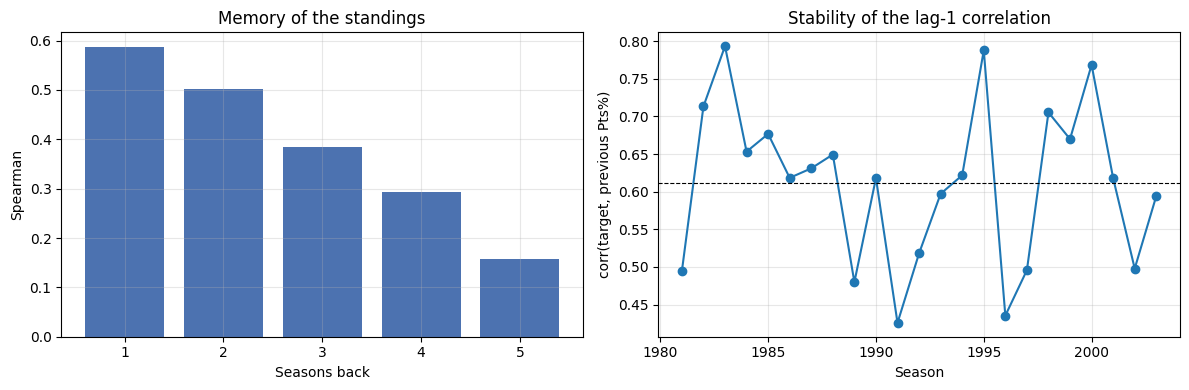

Regression to the mean: target = 0.024 + 0.601 * previous Pts% z-score
-> only ~60% of last season's deviation from the league average is kept.


In [5]:
rows = []
for k in range(1, ru.LAGS + 1):
    sub = dev[dev["n_hist"] >= k]
    rows.append({"lag (seasons back)": k,
                 "spearman with target": sub["target"].corr(sub[f"pts_pct_z_lag{k}"], method="spearman"),
                 "n": len(sub)})
persistence = pd.DataFrame(rows)
display(persistence.round(3))

by_year = {}
for year, g in dev[dev["n_hist"] >= 1].groupby("year"):
    by_year[year] = g["target"].corr(g["pts_pct_z_lag1"])
by_year = pd.Series(by_year)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(persistence["lag (seasons back)"], persistence["spearman with target"], color="#4C72B0")
axes[0].set_xlabel("Seasons back"); axes[0].set_ylabel("Spearman")
axes[0].set_title("Memory of the standings"); axes[0].grid(alpha=.3)
axes[1].plot(by_year.index, by_year.values, marker="o")
axes[1].axhline(by_year.mean(), color="k", ls="--", lw=.8)
axes[1].set_xlabel("Season"); axes[1].set_ylabel("corr(target, previous Pts%)")
axes[1].set_title("Stability of the lag-1 correlation"); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

sub = dev[dev["n_hist"] >= 1]
slope, intercept = np.polyfit(sub["pts_pct_z_lag1"], sub["target"], 1)
print(f"Regression to the mean: target = {intercept:.3f} + {slope:.3f} * previous Pts% z-score")
print(f"-> only ~{slope:.0%} of last season's deviation from the league average is kept.")

## 5. Which history window is useful?

Simple, parameter-free scores used to rank teams inside each conference on the selection years:
last season only, mean of 2, 3 and 5 seasons, and exponentially decaying weights.

In [6]:
def evaluate_scores(pred):
    ranked = ru.rank_predictions(pred, df)
    return ru.summarise(ru.season_metrics(ranked))

candidates = {"last season": "pts_pct_z_lag1", "mean 2 seasons": "pts_pct_z_mean2",
              "mean 3 seasons": "pts_pct_z_mean3", "mean 5 seasons": "pts_pct_z_mean5",
              "exp. decay (0.5)": "pts_pct_z_ewm"}
window_table = pd.DataFrame({
    name: evaluate_scores(ru.baseline_scores(df[df["year"] < ru.TEST_START_YEAR], col, SELECTION_YEARS))
    for name, col in candidates.items()
}).T
print(f"Random ranking of 15 teams: MAE = {ru.random_ranking_mae(15):.2f}, top-8 overlap = {8/15:.2f}")
display(window_table.round(3))

lag_cols = [f"pts_pct_z_lag{k}" for k in range(1, ru.LAGS + 1)]
train_ols = dev[(dev["year"] < SELECTION_YEARS[0]) & (dev["n_hist"] >= ru.LAGS)]
if len(train_ols):
    ols = make_pipeline(StandardScaler(), Ridge(alpha=1e-6)).fit(train_ols[lag_cols], train_ols["target"])
    print("Linear weights on the 5 previous seasons (fit before the selection years):")
    print({c: round(float(w), 3) for c, w in zip(lag_cols, ols[-1].coef_)})

Random ranking of 15 teams: MAE = 4.98, top-8 overlap = 0.53


,mae,rmse,spearman,top_overlap,within_2
last season,2.904,3.725,0.561,0.712,0.536
mean 2 seasons,2.695,3.488,0.605,0.721,0.577
mean 3 seasons,2.912,3.668,0.563,0.694,0.536
mean 5 seasons,3.216,4.028,0.490,0.677,0.460
exp. decay (0.5),2.862,3.668,0.571,0.721,0.558


Linear weights on the 5 previous seasons (fit before the selection years):
{'pts_pct_z_lag1': 0.382, 'pts_pct_z_lag2': 0.223, 'pts_pct_z_lag3': -0.013, 'pts_pct_z_lag4': 0.064, 'pts_pct_z_lag5': -0.111}


## 6. Which features carry signal?

### 6.1 Univariate signal

Spearman correlation of each feature with the season target, on development seasons only. The bars
are coloured by block; the table keeps the 15 strongest features.

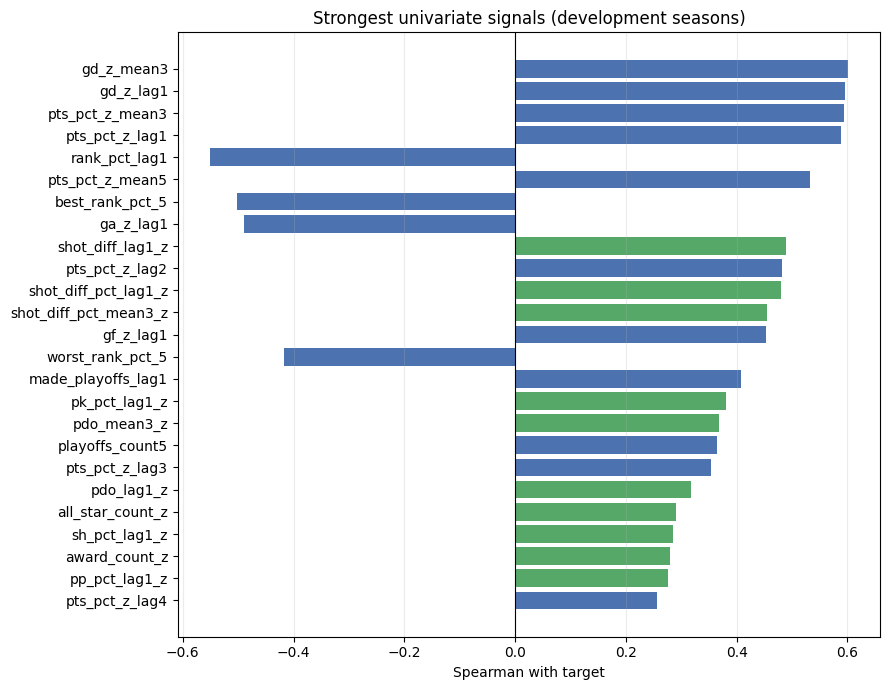

,block,spearman
gd_z_mean3,goals,0.601
gd_z_lag1,goals,0.596
pts_pct_z_mean3,history_points,0.594
pts_pct_z_lag1,prev_points,0.587
rank_pct_lag1,rank_history,-0.551
pts_pct_z_mean5,history_points,0.532
best_rank_pct_5,rank_history,-0.502
ga_z_lag1,goals,-0.490
shot_diff_lag1_z,shots_luck,0.488
pts_pct_z_lag2,history_points,0.482


In [7]:
sub = dev[dev["n_hist"] >= 1]
corr = pd.Series({f: sub[f].corr(sub["target"], method="spearman") for f in ALL_FEATURES})
block = {}
for name, cols in ALL_GROUPS.items():
    for c in cols:
        block[c] = name

block_colors = {
    "prev_points": "#4C72B0", "history_points": "#4C72B0", "trend": "#4C72B0",
    "rank_history": "#4C72B0", "goals": "#4C72B0", "playoffs": "#4C72B0",
    "experience": "#4C72B0", "shots_luck": "#55A868", "goalie": "#55A868",
    "special_teams": "#55A868", "playoff_history": "#55A868",
    "awards": "#55A868", "splits": "#55A868",
}

top = corr.reindex(corr.abs().sort_values(ascending=False).head(25).index)
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index[::-1], top.values[::-1],
        color=[block_colors.get(block[c], "#8C8C8C") for c in top.index[::-1]])
ax.axvline(0, color="black", lw=.8)
ax.set_xlabel("Spearman with target")
ax.set_title("Strongest univariate signals (development seasons)")
ax.grid(axis="x", alpha=.25)
plt.tight_layout(); plt.show()

table = pd.DataFrame({
    "block": [block[c] for c in corr.abs().sort_values(ascending=False).head(15).index],
    "spearman": corr.reindex(corr.abs().sort_values(ascending=False).head(15).index).round(3),
})
display(table)

### 6.2 Collinearity

The heatmap focuses on the base history features and the shots/luck block, the most likely final
candidates. Pairs with `|corr| > 0.9` are redundant for a linear model.

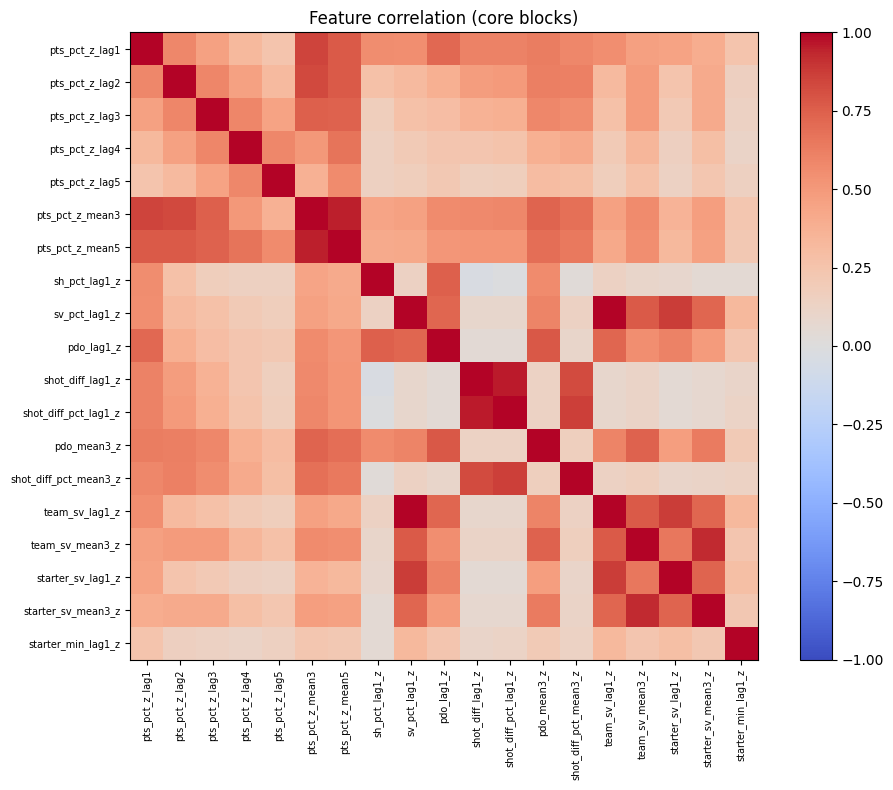

Pairs with |corr| > 0.9:
  sv_pct_lag1_z              team_sv_lag1_z             +1.00
  shot_diff_lag1_z           shot_diff_pct_lag1_z       +0.96
  pts_pct_z_mean3            pts_pct_z_mean5            +0.95
  team_sv_mean3_z            starter_sv_mean3_z         +0.93


In [8]:
core = BASE_FEATURES + EXT_GROUPS["shots_luck"] + EXT_GROUPS["goalie"]
cm = sub[core].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(cm.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cm))); ax.set_xticklabels(cm.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(cm))); ax.set_yticklabels(cm.columns, fontsize=7)
fig.colorbar(im); ax.set_title("Feature correlation (core blocks)"); plt.tight_layout(); plt.show()

pairs = [(a, b, cm.loc[a, b]) for i, a in enumerate(cm.columns)
         for b in cm.columns[i + 1:] if abs(cm.loc[a, b]) > 0.9]
print("Pairs with |corr| > 0.9:")
for a, b, c in sorted(pairs, key=lambda t: -abs(t[2])):
    print(f"  {a:26s} {b:26s} {c:+.2f}")

### 6.3 Leak audit

This cell is a guardrail. It fails if a coach or current-season roster column ever enters the
feature set, and it lists the columns that are used only for the target or for evaluation.

In [9]:
FORBIDDEN = ("coach", "roster", "top3_f", "top6_f", "top4_d", "continuity")
forbidden = [c for c in ALL_FEATURES if any(p in c.lower() for p in FORBIDDEN)]
print("Forbidden feature columns found:", forbidden)
assert not forbidden, "A coach or current-season roster column leaked into the features."

coach_columns = ["coach_changed", "previous_coach_tenure",
                 "previous_coach_interim", "coaches_last_3y"]
present = [c for c in coach_columns if c in teams.columns]
print("Coach columns present in data_prepared but excluded from the features:", present)
print("Current-season columns used only for target/evaluation:",
      ["Pts", "W", "GF", "GA", "playoff", "pts_pct", "win_pct", "conf_rank"])

Forbidden feature columns found: []
Coach columns present in data_prepared but excluded from the features: ['coach_changed']
Current-season columns used only for target/evaluation: ['Pts', 'W', 'GF', 'GA', 'playoff', 'pts_pct', 'win_pct', 'conf_rank']


## 7. External blocks: incremental value

For each external block, we add it to the base team-history features and compare the walk-forward
MAE on the selection years (1995–2004). The confidence interval is a paired bootstrap over whole
`(season, conference)` rankings. A block is interesting only if the interval is clearly above 0.

All these blocks are lagged, so they are leak-free. There is no roster-composition block and no
coach-record block anymore.

In [10]:
ridge = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))


def evaluate(features, years):
    pred = ru.walk_forward(df, ridge, features, years)
    ranked = ru.rank_predictions(pred, df)
    return ru.summarise(ru.season_metrics(ranked)), ranked


def gain_vs_base(features, base_ranked, years):
    _, ranked = evaluate(features, years)
    key = ["year", "tmID"]
    b = base_ranked.set_index(key).sort_index()
    r = ranked.set_index(key).sort_index()
    gid = (b["confID"] + "-" + b.index.get_level_values("year").astype(str)).to_numpy()
    gain, (lo, hi) = ru.paired_bootstrap(
        b["abs_err"].to_numpy(), r["abs_err"].reindex(b.index).to_numpy(), gid)
    return gain, lo, hi


base_summary, base_ranked = evaluate(BASE_FEATURES, SELECTION_YEARS)
rows = [{"block": "base (history only)", "n": len(BASE_FEATURES),
         "mae": base_summary["mae"], "spearman": base_summary["spearman"],
         "gain": 0.0, "ci_low": 0.0, "ci_high": 0.0}]
for name, cols in EXT_GROUPS.items():
    s, _ = evaluate(BASE_FEATURES + cols, SELECTION_YEARS)
    gain, lo, hi = gain_vs_base(BASE_FEATURES + cols, base_ranked, SELECTION_YEARS)
    rows.append({"block": name, "n": len(cols), "mae": s["mae"], "spearman": s["spearman"],
                 "gain": gain, "ci_low": lo, "ci_high": hi})
incremental = pd.DataFrame(rows).sort_values("mae")
incremental["significant"] = incremental["ci_low"] > 0
display(incremental.round(3).set_index("block"))

,n,mae,spearman,gain,ci_low,ci_high,significant
block,,,,,,,
shots_luck,7,2.622,0.624,0.103,-0.048,0.268,False
special_teams,3,2.715,0.605,0.008,-0.095,0.101,False
playoff_history,4,2.719,0.603,0.000,-0.103,0.107,False
base (history only),7,2.722,0.604,0.000,0.000,0.000,False
awards,3,2.742,0.596,-0.024,-0.117,0.080,False
splits,3,2.811,0.583,-0.095,-0.202,-0.008,False
goalie,5,2.891,0.567,-0.166,-0.316,-0.016,False


**Reading the table.**

* **Shots / luck** (shooting %, save %, PDO, shot differential) is the main external signal.
  Shot quality is more repeatable than points and carries information beyond last season's ranking.
* **Goalie**, **special teams**, **playoff history**, **awards** and **splits** are tested
  separately; the greedy selection below decides whether they add anything on top of the selected
  blocks.
* The base here is deliberately simple (last season + longer history). Groups such as goals and
  experience are also available as candidates in the greedy selection.

## 8. Non-linear importance

A shallow gradient boosting is trained on the oldest seasons and evaluated on the following ones.
Permutation importance measures how much validation R² drops when a feature is shuffled. This checks
that the linear selection is not missing a non-linear signal.

train rows: 381 | validation rows: 171 | R2 on validation: 0.423


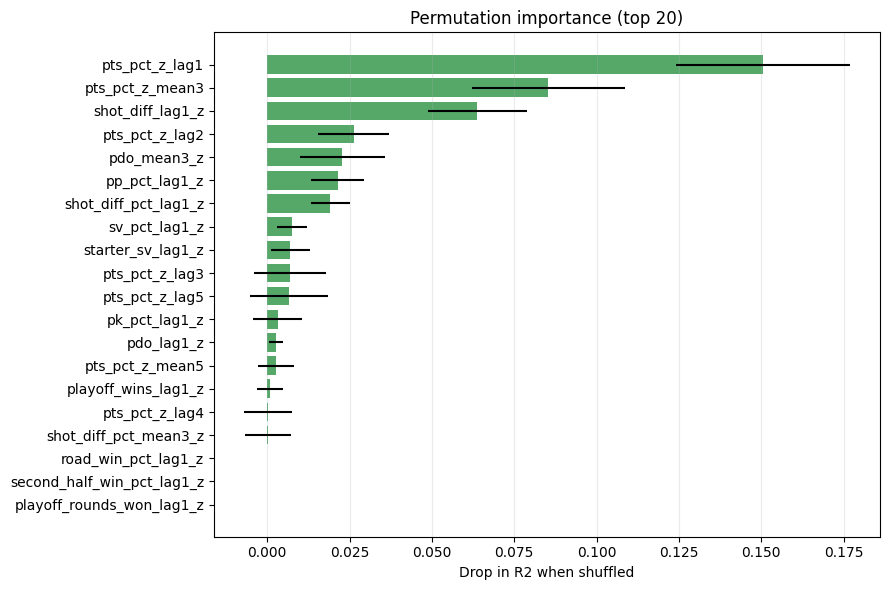

In [11]:
model_features = BASE_FEATURES + EXT_COLS
train = dev[(dev["year"] < 1998) & (dev["n_hist"] >= 1)]
valid = dev[(dev["year"] >= 1998) & (dev["n_hist"] >= 1)]
gbm = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200,
                                    min_samples_leaf=20, l2_regularization=1.0,
                                    random_state=ru.RANDOM_STATE)
gbm.fit(train[model_features], train["target"])
print(f"train rows: {len(train)} | validation rows: {len(valid)} | "
      f"R2 on validation: {gbm.score(valid[model_features], valid['target']):.3f}")

pi = permutation_importance(gbm, valid[model_features], valid["target"],
                            n_repeats=20, random_state=ru.RANDOM_STATE)
importance = pd.Series(pi.importances_mean, index=model_features).sort_values()
top_imp = importance.tail(20)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_imp.index, top_imp.values,
        xerr=pd.Series(pi.importances_std, index=model_features).reindex(top_imp.index),
        color="#55A868")
ax.set_xlabel("Drop in R2 when shuffled")
ax.set_title("Permutation importance (top 20)")
ax.grid(axis="x", alpha=.25)
plt.tight_layout(); plt.show()

## 9. Feature-group selection

Greedy forward selection, starting from last season's points percentage. At each step we add the
block that most reduces the walk-forward rank MAE on 1995–2004, and stop when the gain is below
`MIN_GAIN` rank positions. The selection uses only pre-2005 seasons; 2005–2009 is never touched here.

In [12]:
MIN_GAIN = 0.01


def selection_mae(group_names):
    features = ru.flatten(ALL_GROUPS, group_names)
    pred = ru.walk_forward(df[df["year"] < ru.TEST_START_YEAR], ridge, features, SELECTION_YEARS)
    ranked = ru.rank_predictions(pred, df)
    return ru.season_metrics(ranked)["mae"].mean()


selected = ["prev_points"]
best_mae = selection_mae(selected)
steps = [{"added": "prev_points", "mae": best_mae}]
remaining = [g for g in ALL_GROUPS if g not in selected]

while remaining:
    trials = {g: selection_mae(selected + [g]) for g in remaining}
    candidate = min(trials, key=trials.get)
    print(f"selected={selected} (MAE {best_mae:.3f}) -> best addition: {candidate} ({trials[candidate]:.3f})")
    if best_mae - trials[candidate] < MIN_GAIN:
        break
    selected.append(candidate)
    best_mae = trials[candidate]
    steps.append({"added": candidate, "mae": best_mae})
    remaining.remove(candidate)

display(pd.DataFrame(steps).round(3))
selected_features = ru.flatten(ALL_GROUPS, selected)
print("\nSelected groups  :", selected)
print("Selected features:", selected_features)

with open(ru.SELECTED_FEATURES_PATH, "w") as f:
    json.dump({
        "selected_groups": selected,
        "features": selected_features,
        "base_groups": BASE_GROUPS,
        "base_features": BASE_FEATURES,
    }, f, indent=2)
print(f"Saved -> {ru.SELECTED_FEATURES_PATH.name}")

selected=['prev_points'] (MAE 2.904) -> best addition: shots_luck (2.632)


selected=['prev_points', 'shots_luck'] (MAE 2.632) -> best addition: experience (2.611)


selected=['prev_points', 'shots_luck', 'experience'] (MAE 2.611) -> best addition: rank_history (2.604)


,added,mae
0,prev_points,2.904
1,shots_luck,2.632
2,experience,2.611



Selected groups  : ['prev_points', 'shots_luck', 'experience']
Selected features: ['pts_pct_z_lag1', 'sh_pct_lag1_z', 'sv_pct_lag1_z', 'pdo_lag1_z', 'shot_diff_lag1_z', 'shot_diff_pct_lag1_z', 'pdo_mean3_z', 'shot_diff_pct_mean3_z', 'n_hist']
Saved -> selected_features.json


## 10. Conclusions

**What is worth using**

| Block | Verdict | Why |
|---|---|---|
| Previous points percentage (`pts_pct_z_lag1`) | keep | strongest single history signal |
| Longer history (`lag2`–`lag5`, means) | optional | useful but partly redundant with previous points |
| Shots / luck (PDO, shot differential) | **keep** | main external signal; repeatable shot quality |
| Goals / goal differential | keep if selected | captures performance beyond points |
| Experience (`n_hist`) | keep if selected | new franchises are harder to predict |
| Special teams, goalie, playoff history, awards, splits | only if selected | tested; the gain is generally small |
| Coach columns | **excluded** | target of the coach task; would leak the current season |
| Current-season roster composition | **excluded** | only known after the season (in-season arrivals) |

**What this means for the models**

* The final feature set is **short and leak-free**: last season's points percentage, shots/luck and
  possibly a small number of base groups. The prediction notebook uses exactly this set.
* Points percentage is the right target: it is comparable across shortened and normal seasons.
* The selection uses 1995–2004. The prediction notebook keeps 2005–2009 as the clean test and adds a
  1995–2009 backtest as a stability/power check.
* With leaks removed, the external gain is smaller than in a naive roster-based analysis. That is
  expected: the leak-free model only uses information that is genuinely available before the season.
* **Data caveat**: all “external” features are still internal to the provided hockey tables. Market
  information (preseason win totals, injuries, payroll) is not available here and is the next real
  lever for a larger gain.